In [1]:
!pip -q install kagglehub

import os, re, glob, time, warnings, random
import xml.etree.ElementTree as ET
import numpy as np, pandas as pd, cv2
import matplotlib.pyplot as plt, seaborn as sns
from IPython.display import display, Markdown

from skimage.feature import hog
from skimage import exposure
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, classification_report, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore")
SEED = 42
random.seed(SEED); np.random.seed(SEED)
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

# ---------------- configuration ----------------
IMG = 64                   # common resolution (pixels) for the binary patch classifier
IMG_FULL = 128             # common resolution for whole-image (multi-class) classifier
MAX_DEFECT_PER_IMG = 2     # defect patches taken per source image
NORMALS_PER_IMG = 3        # defect-free patches taken per source image (when available)
TARGET_RECALL = 0.95       # QC policy: catch >= 95 % of defects (missing a defect is costly)
TOPK = 3                   # whole-image decision = mean of the top-k window scores
print("Setup done.")

Setup done.


## 1. Dataset (automatic download)

In [2]:

if "DATA_ROOT" not in globals():
    candidates = ["sovitrath/neu-steel-surface-defect-detecttrainvalid-split",
                  "sovitrath/neu-steel-surface-defect-detect-trainvalid-split"]
    DATA_ROOT = None
    try:
        import kagglehub
        for slug in candidates:
            try:
                DATA_ROOT = kagglehub.dataset_download(slug)
                print("Downloaded:", slug); break
            except Exception as e:
                print("Could not fetch", slug, "->", type(e).__name__)
    except Exception as e:
        print("kagglehub unavailable:", e)

    if DATA_ROOT is None:
        print("\nAutomatic download failed. Please upload the dataset ZIP from Kaggle.")
        from google.colab import files
        up = files.upload()
        import zipfile
        DATA_ROOT = "/content/neu_data"; os.makedirs(DATA_ROOT, exist_ok=True)
        for name in up:
            with zipfile.ZipFile(name) as z: z.extractall(DATA_ROOT)
print("DATA_ROOT =", DATA_ROOT)

Could not fetch sovitrath/neu-steel-surface-defect-detecttrainvalid-split -> KaggleApiHTTPError
Using Colab cache for faster access to the 'neu-steel-surface-defect-detect-trainvalid-split' dataset.
Downloaded: sovitrath/neu-steel-surface-defect-detect-trainvalid-split
DATA_ROOT = /kaggle/input/neu-steel-surface-defect-detect-trainvalid-split


1800 images, 1800 annotation files, classes: ['crazing', 'inclusion', 'patches', 'pitted_surface', 'rolled-in_scale', 'scratches']


,images,mean_boxes,h,w
label,,,,
crazing,300,2.313333,200,200
inclusion,300,2.946667,200,200
patches,300,2.910000,200,200
pitted_surface,300,1.630000,200,200
rolled-in_scale,300,2.093333,200,200
scratches,300,2.070000,200,200


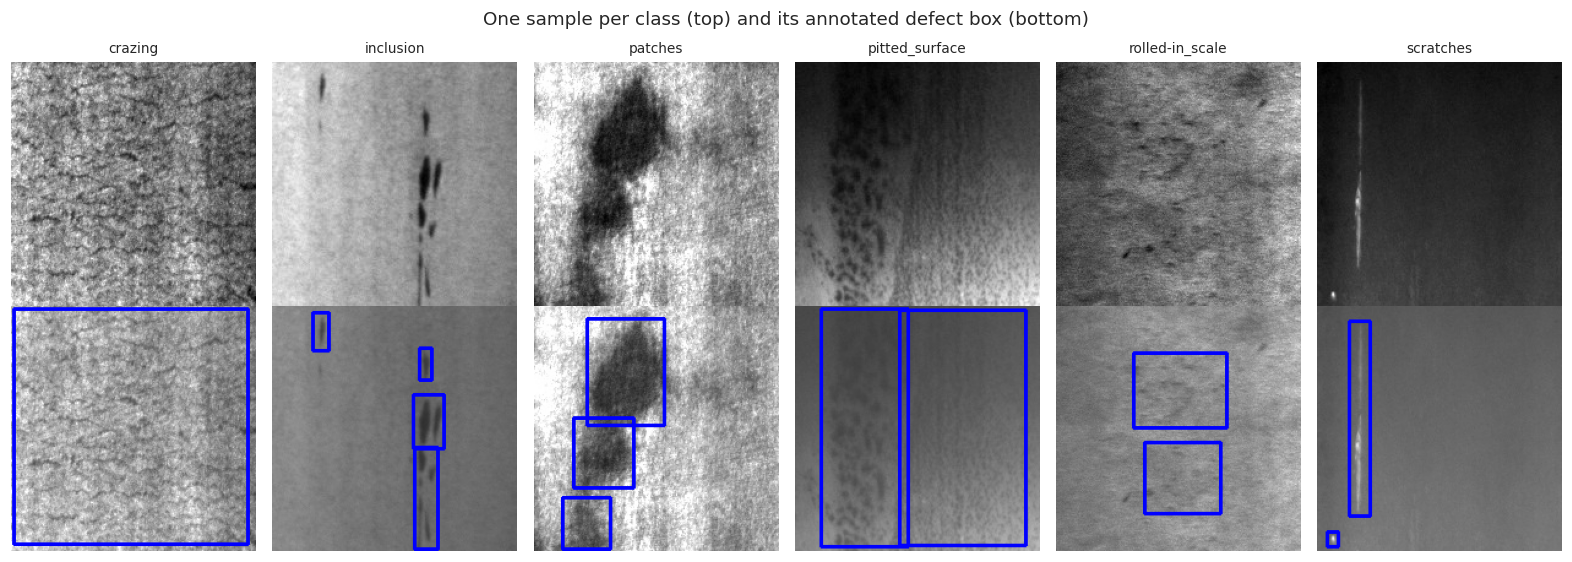

In [3]:
IMG_EXT = {".jpg", ".jpeg", ".png", ".bmp"}
files_all = [p for p in glob.glob(os.path.join(DATA_ROOT, "**", "*"), recursive=True) if os.path.isfile(p)]
img_paths = {os.path.splitext(os.path.basename(p))[0]: p for p in files_all if os.path.splitext(p)[1].lower() in IMG_EXT}
xml_paths = {os.path.splitext(os.path.basename(p))[0]: p for p in files_all if p.lower().endswith(".xml")}

pat = re.compile(r"^(?P<cls>.+?)_\d+$")
stems = sorted(s for s in img_paths if pat.match(s))
label_of = {s: pat.match(s).group("cls") for s in stems}
CLASSES = sorted(set(label_of.values()))
cls2idx = {c: i for i, c in enumerate(CLASSES)}
print(f"{len(stems)} images, {len(xml_paths)} annotation files, classes: {CLASSES}")

def parse_xml(path):
    root = ET.parse(path).getroot()
    boxes = []
    for obj in root.iter("object"):
        bb = obj.find("bndbox")
        boxes.append(tuple(int(float(bb.find(k).text)) for k in ("xmin", "ymin", "xmax", "ymax")))
    return boxes

gray, boxes_of = {}, {}
for s in stems:
    bgr = cv2.imread(img_paths[s], cv2.IMREAD_COLOR)                 # load
    gray[s] = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)                  # grayscale (Task 3)
    H, W = gray[s].shape
    bx = parse_xml(xml_paths[s]) if s in xml_paths else []
    boxes_of[s] = [(max(0, a), max(0, b), min(W, c), min(H, d)) for a, b, c, d in bx]
assert sum(len(v) for v in boxes_of.values()) > 0, "No bounding-box annotations found - the binary (normal vs defective) set needs them."

df = pd.DataFrame({"stem": stems, "label": [label_of[s] for s in stems],
                   "h": [gray[s].shape[0] for s in stems], "w": [gray[s].shape[1] for s in stems],
                   "n_boxes": [len(boxes_of[s]) for s in stems]})
display(df.groupby("label").agg(images=("stem", "count"), mean_boxes=("n_boxes", "mean"), h=("h", "first"), w=("w", "first")))

fig, axes = plt.subplots(2, len(CLASSES), figsize=(2.4 * len(CLASSES), 5.2))
for j, c in enumerate(CLASSES):
    s = df[df.label == c].stem.iloc[0]
    axes[0, j].imshow(gray[s], cmap="gray"); axes[0, j].set_title(c, fontsize=9); axes[0, j].axis("off")
    vis = cv2.cvtColor(gray[s], cv2.COLOR_GRAY2BGR)
    for (x1, y1, x2, y2) in boxes_of[s]: cv2.rectangle(vis, (x1, y1), (x2, y2), (255, 0, 0), 2)
    axes[1, j].imshow(vis[..., ::-1]); axes[1, j].axis("off")
axes[0, 0].set_ylabel("raw"); plt.suptitle("One sample per class (top) and its annotated defect box (bottom)")
plt.tight_layout(); plt.show()

patch 96px -> 1306 defect-free patches available
Chosen patch size P = 96
images  train/val/test = 1260/270/270


,split,non-defective (0),defective (1)
0,train,914,2197
1,val,213,458
2,test,191,462


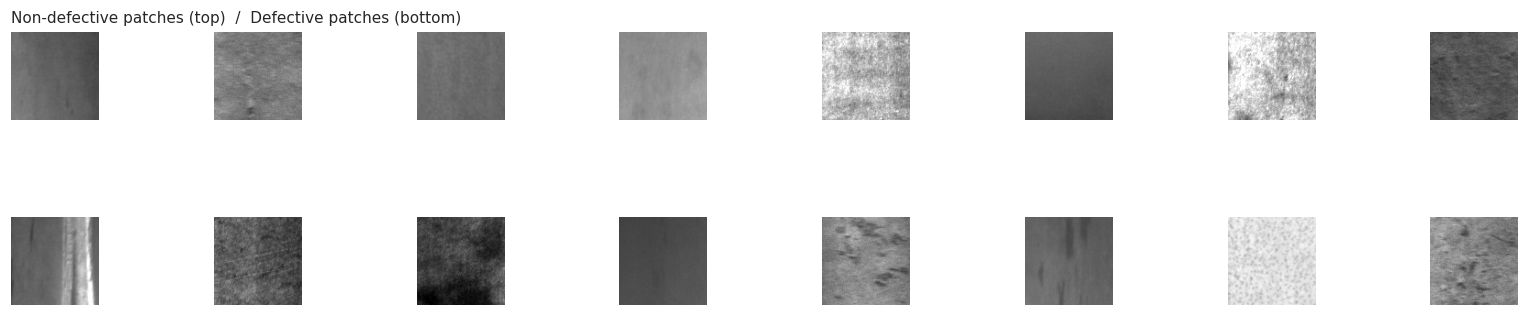

In [4]:
def inter_area(x, y, P, b, margin=4):
    ix = max(0, min(x + P, b[2] + margin) - max(x, b[0] - margin))
    iy = max(0, min(y + P, b[3] + margin) - max(y, b[1] - margin))
    return ix * iy

def make_patches(stem_list, P, seed):
    rng = np.random.RandomState(seed)
    out_x, out_y, out_t, out_s = [], [], [], []
    for s in stem_list:
        g, bxs = gray[s], boxes_of[s]
        H, W = g.shape
        if H < P or W < P: continue

        for i in rng.permutation(len(bxs))[:MAX_DEFECT_PER_IMG]:
            x1, y1, x2, y2 = bxs[i]
            cx, cy = (x1 + x2) // 2, (y1 + y2) // 2
            jx, jy = rng.randint(-P // 4, P // 4 + 1, 2)
            x = int(np.clip(cx - P // 2 + jx, 0, W - P)); y = int(np.clip(cy - P // 2 + jy, 0, H - P))
            out_x.append(g[y:y + P, x:x + P]); out_y.append(1); out_t.append(cls2idx[label_of[s]]); out_s.append(s)

        found = 0
        for _ in range(80):
            x = rng.randint(0, W - P + 1); y = rng.randint(0, H - P + 1)
            if all(inter_area(x, y, P, b) == 0 for b in bxs):
                out_x.append(g[y:y + P, x:x + P]); out_y.append(0); out_t.append(-1); out_s.append(s); found += 1
                if found >= NORMALS_PER_IMG: break
    return np.array(out_x), np.array(out_y), np.array(out_t), np.array(out_s)


MIN_NORMALS = int(0.3 * len(stems))
P, best_cnt = None, -1
for cand in (96, 80, 64, 48):
    _, yy, _, _ = make_patches(stems, cand, SEED)
    n0 = int((yy == 0).sum()); print(f"patch {cand}px -> {n0} defect-free patches available")
    if n0 > best_cnt: best_cnt, bestP = n0, cand
    if n0 >= MIN_NORMALS: P = cand; break
if P is None: P = bestP
print("Chosen patch size P =", P)


labels_arr = np.array([label_of[s] for s in stems]); stems_arr = np.array(stems)
tr_s, tmp_s, _, tmp_l = train_test_split(stems_arr, labels_arr, test_size=0.30, stratify=labels_arr, random_state=SEED)
va_s, te_s = train_test_split(tmp_s, test_size=0.50, stratify=tmp_l, random_state=SEED)
print(f"images  train/val/test = {len(tr_s)}/{len(va_s)}/{len(te_s)}")

Xtr_raw, ytr, ttr, _ = make_patches(tr_s, P, SEED)
Xva_raw, yva, tva, _ = make_patches(va_s, P, SEED + 1)
Xte_raw, yte, tte, ste = make_patches(te_s, P, SEED + 2)
summary = pd.DataFrame({"split": ["train", "val", "test"],
                        "non-defective (0)": [(ytr == 0).sum(), (yva == 0).sum(), (yte == 0).sum()],
                        "defective (1)": [(ytr == 1).sum(), (yva == 1).sum(), (yte == 1).sum()]})
display(summary)

fig, ax = plt.subplots(2, 8, figsize=(14, 3.8))
for k in range(8):
    i0 = np.where(ytr == 0)[0][k * 7 % (ytr == 0).sum()]; i1 = np.where(ytr == 1)[0][k * 11 % (ytr == 1).sum()]
    ax[0, k].imshow(Xtr_raw[i0], cmap="gray", vmin=0, vmax=255); ax[0, k].axis("off")
    ax[1, k].imshow(Xtr_raw[i1], cmap="gray", vmin=0, vmax=255); ax[1, k].axis("off")
ax[0, 0].set_title("Non-defective patches (top)  /  Defective patches (bottom)", loc="left", fontsize=10)
plt.tight_layout(); plt.show()

Preprocessed shapes: (3111, 64, 64) (671, 64, 64) (653, 64, 64)


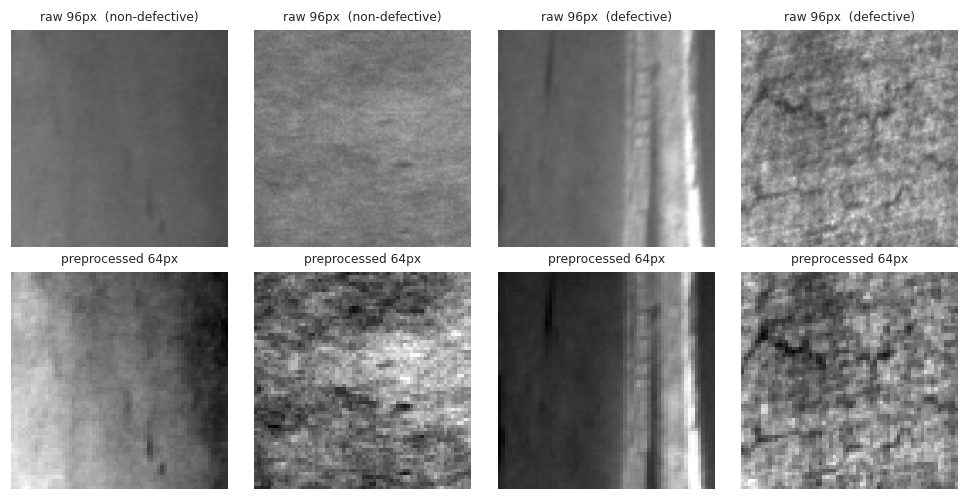

In [5]:
def preprocess(g, size=IMG, normalize=True):
    if g.ndim == 3: g = cv2.cvtColor(g, cv2.COLOR_BGR2GRAY)
    g = cv2.resize(g, (size, size), interpolation=cv2.INTER_AREA)
    if normalize: g = cv2.normalize(g, None, 0, 255, cv2.NORM_MINMAX)
    return g

Xtr_img = np.array([preprocess(p) for p in Xtr_raw]); Xva_img = np.array([preprocess(p) for p in Xva_raw])
Xte_img = np.array([preprocess(p) for p in Xte_raw])
print("Preprocessed shapes:", Xtr_img.shape, Xva_img.shape, Xte_img.shape)

fig, ax = plt.subplots(2, 4, figsize=(9, 4.6))
for k, (i, name) in enumerate([(np.where(ytr == 0)[0][0], "non-defective"), (np.where(ytr == 0)[0][5], "non-defective"),
                               (np.where(ytr == 1)[0][0], "defective"), (np.where(ytr == 1)[0][5], "defective")]):
    ax[0, k].imshow(Xtr_raw[i], cmap="gray", vmin=0, vmax=255); ax[0, k].set_title(f"raw {Xtr_raw[i].shape[0]}px  ({name})", fontsize=8)
    ax[1, k].imshow(Xtr_img[i], cmap="gray", vmin=0, vmax=255); ax[1, k].set_title(f"preprocessed {IMG}px", fontsize=8)
    ax[0, k].axis("off"); ax[1, k].axis("off")
plt.tight_layout(); plt.show()

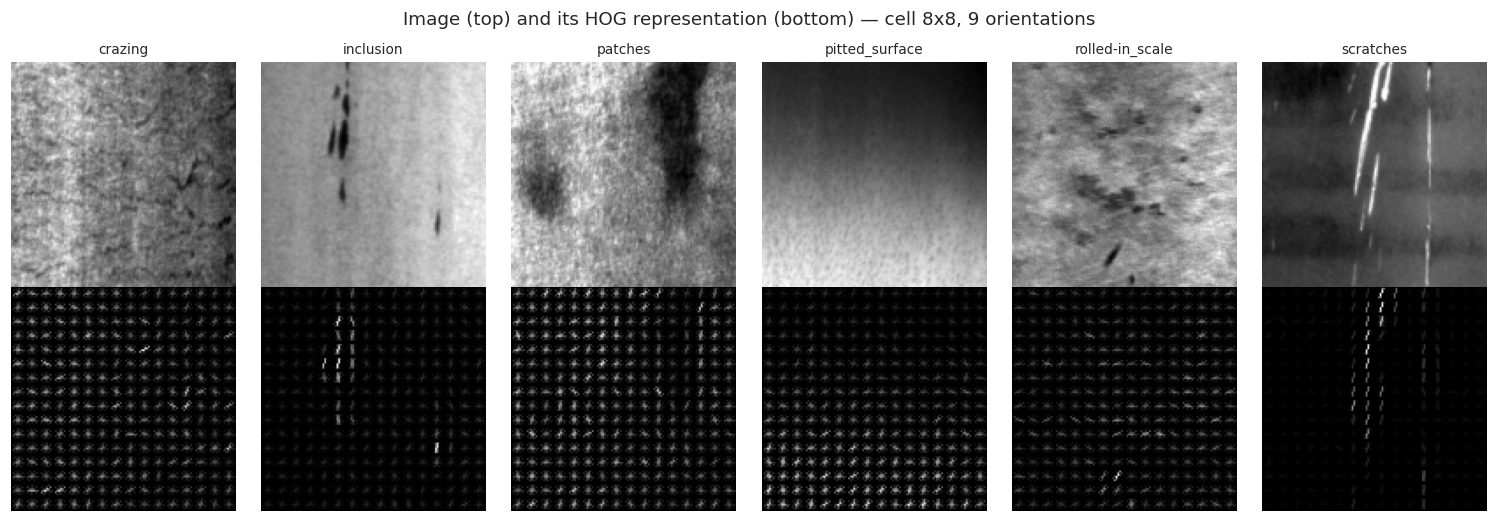

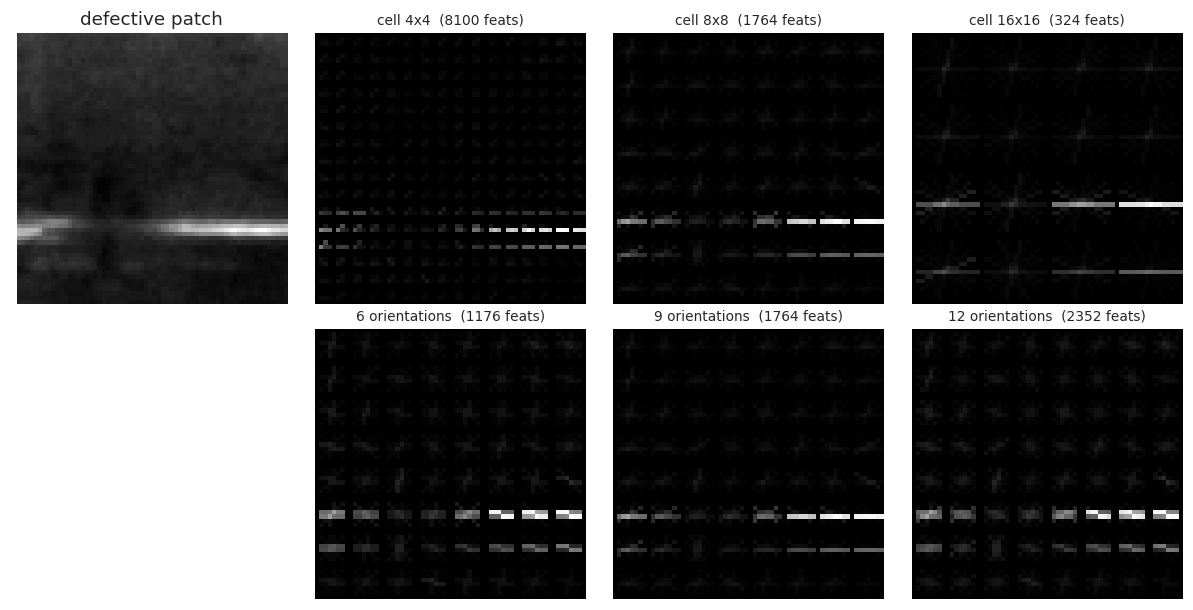

In [6]:
def hog_one(im, cell=8, orient=9, block=2, visualize=False):
    return hog(im, orientations=orient, pixels_per_cell=(cell, cell), cells_per_block=(block, block),
               block_norm="L2-Hys", feature_vector=True, visualize=visualize)

def extract_hog(images, cell=8, orient=9):
    return np.array([hog_one(im, cell, orient) for im in images], dtype=np.float32)

fig, ax = plt.subplots(2, len(CLASSES), figsize=(2.3 * len(CLASSES), 4.8))
for j, c in enumerate(CLASSES):
    s = df[df.label == c].stem.iloc[1]
    im = preprocess(gray[s], IMG_FULL)
    _, hv = hog_one(im, 8, 9, visualize=True)
    ax[0, j].imshow(im, cmap="gray"); ax[0, j].set_title(c, fontsize=9); ax[0, j].axis("off")
    ax[1, j].imshow(exposure.rescale_intensity(hv, in_range=(0, hv.max() + 1e-9)), cmap="gray"); ax[1, j].axis("off")
plt.suptitle("Image (top) and its HOG representation (bottom) — cell 8x8, 9 orientations"); plt.tight_layout(); plt.show()

ex = Xtr_img[np.where(ytr == 1)[0][3]]
fig, ax = plt.subplots(2, 4, figsize=(11, 5.6))
ax[0, 0].imshow(ex, cmap="gray"); ax[0, 0].set_title("defective patch"); ax[0, 0].axis("off")
for k, cell in enumerate((4, 8, 16)):
    f, hv = hog_one(ex, cell, 9, visualize=True)
    ax[0, k + 1].imshow(exposure.rescale_intensity(hv, in_range=(0, hv.max() + 1e-9)), cmap="gray")
    ax[0, k + 1].set_title(f"cell {cell}x{cell}  ({len(f)} feats)", fontsize=9); ax[0, k + 1].axis("off")
ax[1, 0].axis("off")
for k, o in enumerate((6, 9, 12)):
    f, hv = hog_one(ex, 8, o, visualize=True)
    ax[1, k + 1].imshow(exposure.rescale_intensity(hv, in_range=(0, hv.max() + 1e-9)), cmap="gray")
    ax[1, k + 1].set_title(f"{o} orientations  ({len(f)} feats)", fontsize=9); ax[1, k + 1].axis("off")
plt.tight_layout(); plt.show()

In [7]:
def get_model(name, proba=False, C=10):
    if name == "SVM (RBF)":
        return make_pipeline(StandardScaler(), SVC(kernel="rbf", C=C, gamma="scale", class_weight="balanced",
                                                   probability=proba, random_state=SEED))
    if name == "Random Forest":
        return RandomForestClassifier(n_estimators=150, class_weight="balanced", n_jobs=-1, random_state=SEED)
    if name == "Logistic Regression":
        return make_pipeline(StandardScaler(), LogisticRegression(C=0.1, max_iter=2000, class_weight="balanced"))
    if name == "k-NN":
        return make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))

def bin_metrics(y, p):

    return dict(accuracy=accuracy_score(y, p), precision=precision_score(y, p, zero_division=0),
                recall=recall_score(y, p, zero_division=0), f1=f1_score(y, p, zero_division=0),
                macro_f1=f1_score(y, p, average="macro", zero_division=0))

rows = []
feat_cache = {}
for cell in (4, 8, 16):
    for orient in (6, 9, 12):
        t0 = time.time()
        Ftr, Fva = extract_hog(Xtr_img, cell, orient), extract_hog(Xva_img, cell, orient)
        feat_cache[(cell, orient)] = (Ftr, Fva)
        t_hog = time.time() - t0
        for name in ("SVM (RBF)", "Random Forest"):
            t0 = time.time(); m = get_model(name).fit(Ftr, ytr); t_fit = time.time() - t0
            r = bin_metrics(yva, m.predict(Fva))
            rows.append(dict(cell=f"{cell}x{cell}", cell_px=cell, orient=orient, n_features=Ftr.shape[1], model=name,
                             val_acc=r["accuracy"], val_f1=r["f1"], val_macro_f1=r["macro_f1"], fit_s=t_fit, hog_s=t_hog))
        print(f"cell {cell:2d} orient {orient:2d}  feats {Ftr.shape[1]:6d}  done")
grid = pd.DataFrame(rows)
display(grid.round(4))

cell  4 orient  6  feats   5400  done
cell  4 orient  9  feats   8100  done
cell  4 orient 12  feats  10800  done
cell  8 orient  6  feats   1176  done
cell  8 orient  9  feats   1764  done
cell  8 orient 12  feats   2352  done
cell 16 orient  6  feats    216  done
cell 16 orient  9  feats    324  done
cell 16 orient 12  feats    432  done


,cell,cell_px,orient,n_features,model,val_acc,val_f1,val_macro_f1,fit_s,hog_s
0,4x4,4,6,5400,SVM (RBF),0.7899,0.8563,0.7328,67.6104,39.3644
1,4x4,4,6,5400,Random Forest,0.7288,0.8333,0.5527,40.3806,39.3644
2,4x4,4,9,8100,SVM (RBF),0.7869,0.8560,0.7231,73.5049,24.3797
3,4x4,4,9,8100,Random Forest,0.7198,0.8294,0.5230,46.0952,24.3797
4,4x4,4,12,10800,SVM (RBF),0.7899,0.8583,0.7260,116.9727,26.5575
5,4x4,4,12,10800,Random Forest,0.7347,0.8364,0.5678,37.8942,26.5575
6,8x8,8,6,1176,SVM (RBF),0.8182,0.8742,0.7731,8.7781,6.9704
7,8x8,8,6,1176,Random Forest,0.7750,0.8569,0.6654,17.3981,6.9704
8,8x8,8,9,1764,SVM (RBF),0.8063,0.8649,0.7614,14.5663,8.4716
9,8x8,8,9,1764,Random Forest,0.7556,0.8470,0.6198,23.2578,8.4716


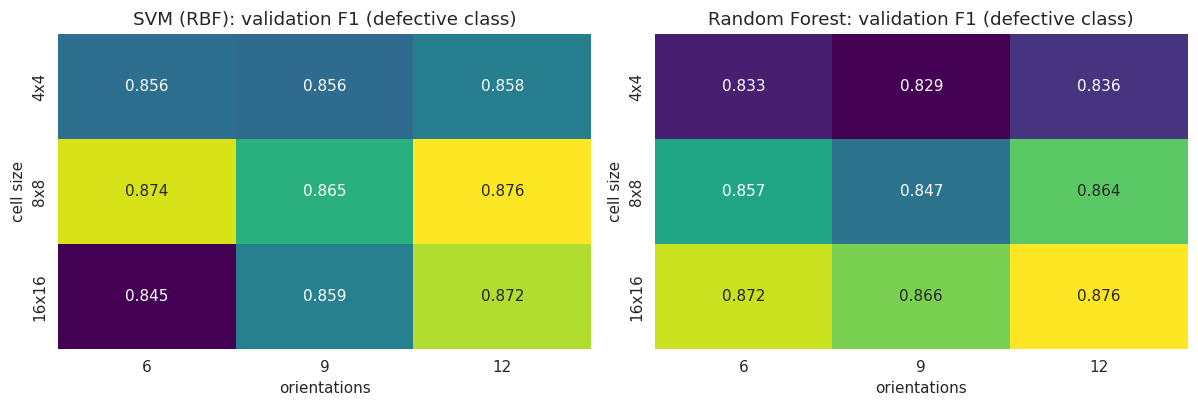

Selected HOG configuration: cell 8x8, 12 orientations (2352 features)


In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for a, name in zip(ax, ("SVM (RBF)", "Random Forest")):
    pv = grid[grid.model == name].pivot(index="cell", columns="orient", values="val_f1").loc[["4x4", "8x8", "16x16"]]
    sns.heatmap(pv, annot=True, fmt=".3f", cmap="viridis", ax=a, cbar=False)
    a.set_title(f"{name}: validation F1 (defective class)"); a.set_xlabel("orientations"); a.set_ylabel("cell size")
plt.tight_layout(); plt.show()

# best HOG configuration = best validation F1 of the SVM (ties -> fewer features)
svm_grid = grid[grid.model == "SVM (RBF)"].sort_values(["val_f1", "n_features"], ascending=[False, True])
BEST_CELL, BEST_ORIENT = int(svm_grid.iloc[0].cell_px), int(svm_grid.iloc[0].orient)
print(f"Selected HOG configuration: cell {BEST_CELL}x{BEST_CELL}, {BEST_ORIENT} orientations "
      f"({int(svm_grid.iloc[0].n_features)} features)")

In [9]:
Ftr, Fva = feat_cache[(BEST_CELL, BEST_ORIENT)]
Fte = extract_hog(Xte_img, BEST_CELL, BEST_ORIENT)

c_rows = []
for C in (1, 10, 100):
    m = get_model("SVM (RBF)", C=C).fit(Ftr, ytr); c_rows.append((C, f1_score(yva, m.predict(Fva))))
BEST_C = max(c_rows, key=lambda t: t[1])[0]
print("SVM C search (val F1):", {c: round(f, 4) for c, f in c_rows}, "-> C =", BEST_C)

models, preds, times = {}, {}, {}
for name in ("SVM (RBF)", "Random Forest", "Logistic Regression", "k-NN"):
    m = get_model(name, proba=(name == "SVM (RBF)"), C=BEST_C)
    t0 = time.time(); m.fit(Ftr, ytr); fit_t = time.time() - t0
    t0 = time.time(); preds[name] = m.predict(Fte); inf_t = (time.time() - t0) / len(Fte) * 1000
    models[name] = m; times[name] = (fit_t, inf_t)

comp = pd.DataFrame({n: bin_metrics(yte, p) for n, p in preds.items()}).T
comp["train_s"] = [times[n][0] for n in comp.index]; comp["ms_per_sample"] = [times[n][1] for n in comp.index]
display(comp.round(4).style.background_gradient(cmap="Greens", subset=["accuracy", "precision", "recall", "f1", "macro_f1"]))

SVM C search (val F1): {1: 0.8757, 10: 0.876, 100: 0.876} -> C = 10


,accuracy,precision,recall,f1,macro_f1,train_s,ms_per_sample
SVM (RBF),0.836100,0.855700,0.924200,0.888700,0.789300,107.348900,6.449500
Random Forest,0.833100,0.811300,0.995700,0.894100,0.750300,23.519700,0.086400
Logistic Regression,0.762600,0.857800,0.796500,0.826000,0.726300,2.244100,0.051200
k-NN,0.657000,0.916100,0.567100,0.700500,0.649600,0.186500,0.652200


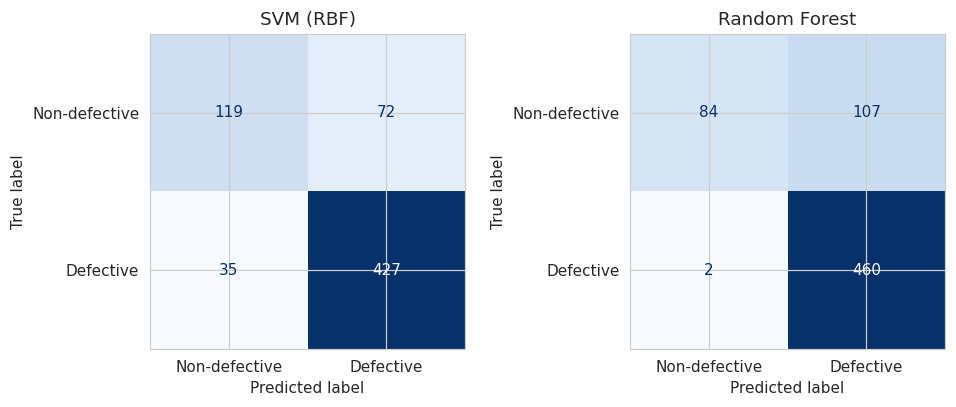


===== SVM (RBF) — classification report (test set) =====
               precision    recall  f1-score   support

Non-defective     0.7727    0.6230    0.6899       191
    Defective     0.8557    0.9242    0.8887       462

     accuracy                         0.8361       653
    macro avg     0.8142    0.7736    0.7893       653
 weighted avg     0.8314    0.8361    0.8305       653


===== Random Forest — classification report (test set) =====
               precision    recall  f1-score   support

Non-defective     0.9767    0.4398    0.6065       191
    Defective     0.8113    0.9957    0.8941       462

     accuracy                         0.8331       653
    macro avg     0.8940    0.7177    0.7503       653
 weighted avg     0.8597    0.8331    0.8100       653

Detection rate (recall) per defect type - SVM:


,recall
crazing,0.964
inclusion,0.924
patches,0.953
pitted_surface,0.954
rolled-in_scale,0.772
scratches,0.986


In [10]:
fig, ax = plt.subplots(1, 2, figsize=(9, 3.8))
for a, name in zip(ax, ("SVM (RBF)", "Random Forest")):
    cm = confusion_matrix(yte, preds[name])
    ConfusionMatrixDisplay(cm, display_labels=["Non-defective", "Defective"]).plot(ax=a, cmap="Blues", colorbar=False, values_format="d")
    a.set_title(name)
plt.tight_layout(); plt.show()

for name in ("SVM (RBF)", "Random Forest"):
    print(f"\n===== {name} — classification report (test set) =====")
    print(classification_report(yte, preds[name], target_names=["Non-defective", "Defective"], digits=4))

dm = (tte >= 0)
rec_type = pd.Series({CLASSES[c]: (preds["SVM (RBF)"][dm & (tte == c)] == 1).mean() for c in np.unique(tte[dm])})
print("Detection rate (recall) per defect type - SVM:"); display(rec_type.round(3).to_frame("recall"))

multi-class feature size: (1260, 8100)


,accuracy,macro_precision,macro_recall,macro_f1
model,,,,
SVM (RBF),0.8593,0.8603,0.8593,0.8560
Random Forest,0.7593,0.7769,0.7593,0.7482



Best multi-class model: SVM (RBF)

                 precision    recall  f1-score   support

        crazing      0.846     0.978     0.907        45
      inclusion      0.808     0.933     0.866        45
        patches      0.833     0.778     0.805        45
 pitted_surface      0.816     0.689     0.747        45
rolled-in_scale      0.938     1.000     0.968        45
      scratches      0.921     0.778     0.843        45

       accuracy                          0.859       270
      macro avg      0.860     0.859     0.856       270
   weighted avg      0.860     0.859     0.856       270



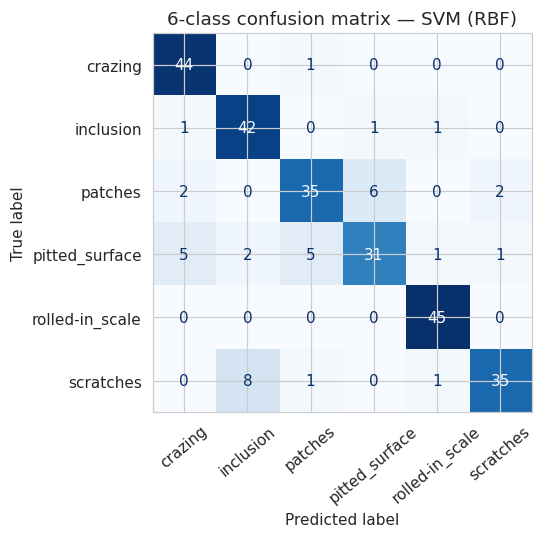

In [11]:
def whole_set(sl): return np.array([preprocess(gray[s], IMG_FULL) for s in sl]), np.array([cls2idx[label_of[s]] for s in sl])
Wtr, wytr = whole_set(tr_s); Wva, wyva = whole_set(va_s); Wte, wyte = whole_set(te_s)
MC_CELL, MC_ORIENT = 8, 9
WFtr, WFva, WFte = (extract_hog(a, MC_CELL, MC_ORIENT) for a in (Wtr, Wva, Wte))
print("multi-class feature size:", WFtr.shape)

mc_models = {"SVM (RBF)": make_pipeline(StandardScaler(), SVC(kernel="rbf", C=10, gamma="scale", random_state=SEED)),
             "Random Forest": RandomForestClassifier(n_estimators=300, n_jobs=-1, random_state=SEED)}
mc_rows, mc_pred = [], {}
for n, m in mc_models.items():
    m.fit(WFtr, wytr); p = m.predict(WFte); mc_pred[n] = p
    mc_rows.append(dict(model=n, accuracy=accuracy_score(wyte, p), macro_precision=precision_score(wyte, p, average="macro"),
                        macro_recall=recall_score(wyte, p, average="macro"), macro_f1=f1_score(wyte, p, average="macro")))
mc_df = pd.DataFrame(mc_rows).set_index("model"); display(mc_df.round(4))

best_mc = mc_df.macro_f1.idxmax(); svm_multi = mc_models[best_mc]
print(f"\nBest multi-class model: {best_mc}\n")
print(classification_report(wyte, mc_pred[best_mc], target_names=CLASSES, digits=3))
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(confusion_matrix(wyte, mc_pred[best_mc]), display_labels=CLASSES).plot(ax=ax, cmap="Blues", colorbar=False, xticks_rotation=40)
ax.set_title(f"6-class confusion matrix — {best_mc}"); plt.tight_layout(); plt.show()

Baseline (clean test set):


,accuracy,f1
SVM (RBF),0.8361,0.8887
Random Forest,0.8331,0.8941


,model,condition,level,accuracy,f1,d_acc,d_f1
0,SVM (RBF),Brightness,darker x0.6,0.810100,0.858800,-0.026000,-0.029900
1,Random Forest,Brightness,darker x0.6,0.853000,0.901600,0.019900,0.007600
2,SVM (RBF),Brightness,brighter x1.5,0.819300,0.883600,-0.016800,-0.005000
3,Random Forest,Brightness,brighter x1.5,0.781000,0.865700,-0.052100,-0.028300
4,SVM (RBF),Brightness,offset +50,0.831500,0.885900,-0.004600,-0.002800
5,Random Forest,Brightness,offset +50,0.831500,0.893200,-0.001500,-0.000900
6,SVM (RBF),Gaussian noise,sigma=10,0.751900,0.838000,-0.084200,-0.050700
7,Random Forest,Gaussian noise,sigma=10,0.710600,0.829900,-0.122500,-0.064200
8,SVM (RBF),Gaussian noise,sigma=25,0.689100,0.811900,-0.147000,-0.076800
9,Random Forest,Gaussian noise,sigma=25,0.707500,0.828700,-0.125600,-0.065400


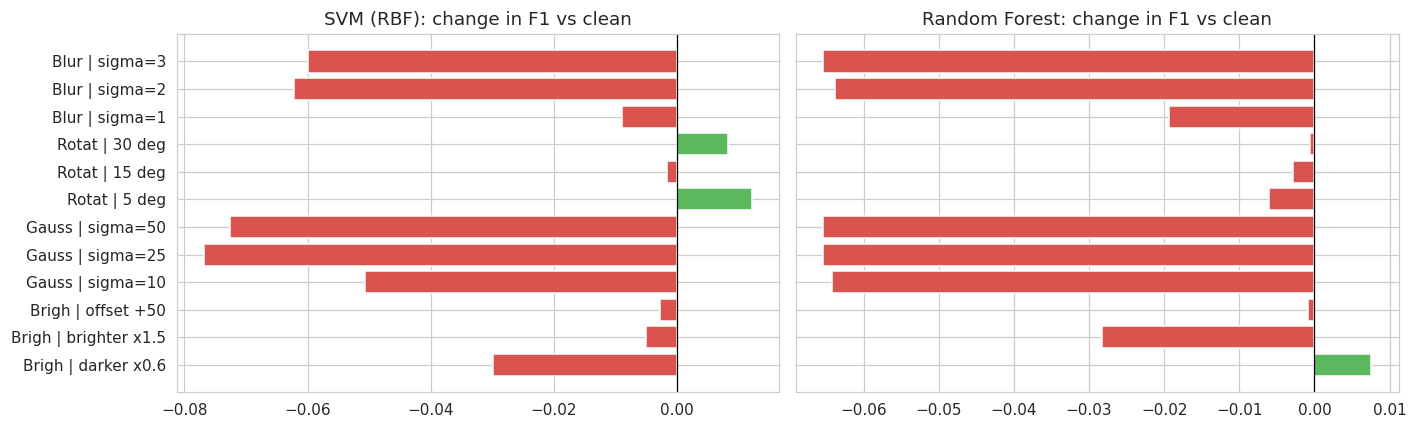

In [12]:
def adj_bright(im, alpha=1.0, beta=0): return np.clip(im.astype(np.float32) * alpha + beta, 0, 255).astype(np.uint8)
def add_noise(im, sigma, rs):         return np.clip(im.astype(np.float32) + rs.normal(0, sigma, im.shape), 0, 255).astype(np.uint8)
def rotate(im, ang):
    h, w = im.shape; M = cv2.getRotationMatrix2D((w / 2, h / 2), ang, 1.0)
    return cv2.warpAffine(im, M, (w, h), flags=cv2.INTER_LINEAR, borderMode=cv2.BORDER_REFLECT_101)
def blur(im, sigma):                  return cv2.GaussianBlur(im, (0, 0), sigma)

rs = np.random.RandomState(SEED)
conditions = {
    "Brightness": [("darker x0.6", lambda im: adj_bright(im, 0.6)), ("brighter x1.5", lambda im: adj_bright(im, 1.5)), ("offset +50", lambda im: adj_bright(im, 1.0, 50))],
    "Gaussian noise": [(f"sigma={s}", (lambda im, s=s: add_noise(im, s, rs))) for s in (10, 25, 50)],
    "Rotation": [(f"{a} deg", (lambda im, a=a: rotate(im, a))) for a in (5, 15, 30)],
    "Blur": [(f"sigma={s}", (lambda im, s=s: blur(im, s))) for s in (1, 2, 3)],
}
rob_models = ["SVM (RBF)", "Random Forest"]
base = {n: bin_metrics(yte, models[n].predict(Fte)) for n in rob_models}
rob_rows = []
for cond, levels in conditions.items():
    for lvl, fn in levels:
        Xp = np.array([preprocess(fn(im)) for im in Xte_raw])
        Fp = extract_hog(Xp, BEST_CELL, BEST_ORIENT)
        for n in rob_models:
            r = bin_metrics(yte, models[n].predict(Fp))
            rob_rows.append(dict(model=n, condition=cond, level=lvl, accuracy=r["accuracy"], f1=r["f1"],
                                 d_acc=r["accuracy"] - base[n]["accuracy"], d_f1=r["f1"] - base[n]["f1"]))
rob = pd.DataFrame(rob_rows)
print("Baseline (clean test set):"); display(pd.DataFrame(base).T[["accuracy", "f1"]].round(4))
display(rob.round(4).style.background_gradient(cmap="RdYlGn", subset=["d_acc", "d_f1"]))

fig, ax = plt.subplots(1, 2, figsize=(13, 4), sharey=True)
for a, n in zip(ax, rob_models):
    d = rob[rob.model == n]; labels = (d.condition.str[:5] + " | " + d.level).values
    a.barh(labels, d.d_f1.values, color=np.where(d.d_f1.values < 0, "#d9534f", "#5cb85c"))
    a.axvline(0, color="k", lw=.8); a.set_title(f"{n}: change in F1 vs clean"); a.invert_yaxis()
plt.tight_layout(); plt.show()

Policy threshold (val recall >= 95%): 0.41


,accuracy,precision,recall,f1,macro_f1
threshold 0.50,0.8346,0.8484,0.9329,0.8887,0.7836
threshold 0.41 (QC policy),0.8469,0.8428,0.9632,0.8990,0.7913



--- defect-free patch ---
PRODUCT INSPECTION RESULT
Prediction: DEFECTIVE
Confidence: 79.3%
Action: REJECT PRODUCT

--- defect-free patch ---
PRODUCT INSPECTION RESULT
Prediction: DEFECTIVE
Confidence: 87.5%
Action: REJECT PRODUCT

--- defective patch ---
PRODUCT INSPECTION RESULT
Prediction: DEFECTIVE
Confidence: 97.7%
Action: REJECT PRODUCT

--- defective patch ---
PRODUCT INSPECTION RESULT
Prediction: DEFECTIVE
Confidence: 97.6%
Action: REJECT PRODUCT

--- whole product image ---
PRODUCT INSPECTION RESULT
Prediction: DEFECTIVE
Confidence: 96.9%
Action: REJECT PRODUCT   (likely defect type: patches)

--- whole product image ---
PRODUCT INSPECTION RESULT
Prediction: DEFECTIVE
Confidence: 99.7%
Action: REJECT PRODUCT   (likely defect type: scratches)


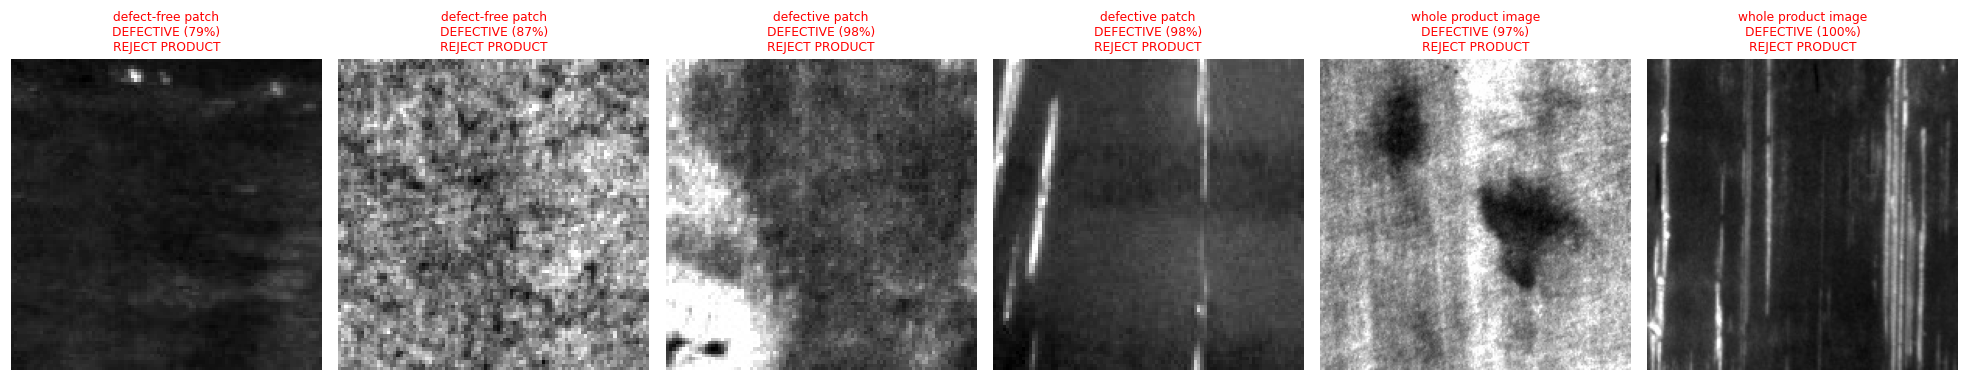


Whole-image test: 99.6% of the 270 defective test products were REJECTED   (~176 ms / product)
(NEU-DET contains no defect-free whole images, so a product-level false-reject rate cannot be measured; the patch-level results above cover that.)


In [13]:
svm_bin = models["SVM (RBF)"]
pv = svm_bin.predict_proba(Fva)[:, 1]
THRESH = 0.5
for t in np.arange(0.95, 0.04, -0.01):
    if recall_score(yva, pv >= t) >= TARGET_RECALL: THRESH = float(round(t, 2)); break
pt = svm_bin.predict_proba(Fte)[:, 1]
r_default, r_policy = bin_metrics(yte, (pt >= 0.5).astype(int)), bin_metrics(yte, (pt >= THRESH).astype(int))
print(f"Policy threshold (val recall >= {TARGET_RECALL:.0%}): {THRESH}")
display(pd.DataFrame({"threshold 0.50": r_default, f"threshold {THRESH} (QC policy)": r_policy}).T.round(4))

def to_gray(img): return cv2.cvtColor(img, cv2.COLOR_BGR2GRAY) if img.ndim == 3 else img

def scan_windows(g, P, stride=None):
    H, W = g.shape; stride = stride or max(1, P // 2)
    if max(H, W) <= int(P * 1.15):                                      # single patch input
        return [cv2.resize(g, (P, P), interpolation=cv2.INTER_AREA)], [(0, 0)]
    ys = list(range(0, H - P + 1, stride)); xs = list(range(0, W - P + 1, stride))
    if ys[-1] != H - P: ys.append(H - P)
    if xs[-1] != W - P: xs.append(W - P)
    return [g[y:y + P, x:x + P] for y in ys for x in xs], [(x, y) for y in ys for x in xs]

def inspect_product(img, threshold=None, verbose=True, return_windows=False):
    threshold = THRESH if threshold is None else threshold
    g = to_gray(img)
    wins, coords = scan_windows(g, P)
    F = extract_hog([preprocess(w) for w in wins], BEST_CELL, BEST_ORIENT)
    p = svm_bin.predict_proba(F)[:, 1]
    score = float(np.sort(p)[-min(TOPK, len(p)):].mean())
    defective = score >= threshold
    conf = (score if defective else 1 - score) * 100
    dtype = None
    if defective and len(wins) > 1:                                     # whole image -> also say what kind of defect
        wf = extract_hog([preprocess(g, IMG_FULL)], MC_CELL, MC_ORIENT)
        dtype = CLASSES[int(svm_multi.predict(wf)[0])]
    res = dict(prediction="DEFECTIVE" if defective else "NON-DEFECTIVE", confidence=conf, score=score,
               action="REJECT PRODUCT" if defective else "ACCEPT PRODUCT", defect_type=dtype)
    if verbose:
        print("PRODUCT INSPECTION RESULT")
        print(f"Prediction: {res['prediction']}")
        print(f"Confidence: {conf:.1f}%")
        print(f"Action: {res['action']}" + (f"   (likely defect type: {dtype})" if dtype else ""))
    return (res, p, coords) if return_windows else res

# ---- demo: 2 defect-free patches, 2 defective patches, 2 whole defective images from the test split
rng = np.random.RandomState(1)
demo = [("defect-free patch", Xte_raw[rng.choice(np.where(yte == 0)[0])]) for _ in range(2)] + \
       [("defective patch", Xte_raw[rng.choice(np.where(yte == 1)[0])]) for _ in range(2)] + \
       [("whole product image", gray[s]) for s in te_s[[0, len(te_s) // 2]]]
fig, ax = plt.subplots(1, len(demo), figsize=(3 * len(demo), 3.4))
for a, (kind, im) in zip(ax, demo):
    print(f"\n--- {kind} ---"); r = inspect_product(im)
    a.imshow(im, cmap="gray"); a.axis("off")
    a.set_title(f"{kind}\n{r['prediction']} ({r['confidence']:.0f}%)\n{r['action']}", fontsize=8, color="red" if r["prediction"] == "DEFECTIVE" else "green")
plt.tight_layout(); plt.show()

t0 = time.time(); res_img = [inspect_product(gray[s], verbose=False) for s in te_s]; dt = (time.time() - t0) / len(te_s)
det_rate = np.mean([r["prediction"] == "DEFECTIVE" for r in res_img])
print(f"\nWhole-image test: {det_rate:.1%} of the {len(te_s)} defective test products were REJECTED   (~{dt*1000:.0f} ms / product)")
print("(NEU-DET contains no defect-free whole images, so a product-level false-reject rate cannot be measured; the patch-level results above cover that.)")

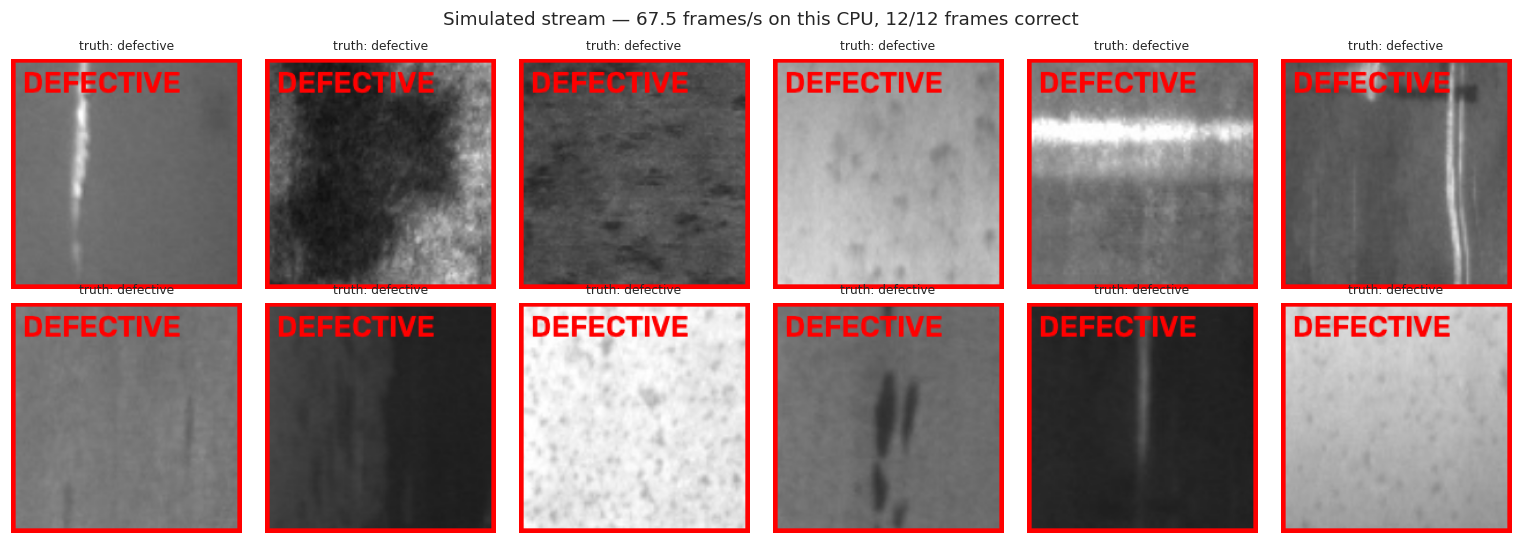

In [14]:
# (a) simulated stream: frames are processed one by one, each gets a PASS / DEFECTIVE overlay
rng = np.random.RandomState(7)
idx = rng.choice(len(Xte_raw), 12, replace=False)
fig, ax = plt.subplots(2, 6, figsize=(14, 5)); t0 = time.time(); correct = 0
for a, i in zip(ax.ravel(), idx):
    frame = cv2.cvtColor(cv2.resize(Xte_raw[i], (200, 200)), cv2.COLOR_GRAY2BGR)
    r = inspect_product(Xte_raw[i], verbose=False)
    ok = (r["prediction"] == "DEFECTIVE") == bool(yte[i]); correct += ok
    status = "DEFECTIVE" if r["prediction"] == "DEFECTIVE" else "PASS"; colour = (0, 0, 255) if status == "DEFECTIVE" else (0, 160, 0)
    cv2.rectangle(frame, (0, 0), (199, 199), colour, 6); cv2.putText(frame, status, (10, 30), cv2.FONT_HERSHEY_SIMPLEX, 0.9, colour, 2)
    a.imshow(frame[..., ::-1]); a.axis("off"); a.set_title(f"truth: {'defective' if yte[i] else 'ok'}", fontsize=8)
fps = len(idx) / (time.time() - t0)
plt.suptitle(f"Simulated stream — {fps:.1f} frames/s on this CPU, {correct}/{len(idx)} frames correct"); plt.tight_layout(); plt.show()

In [15]:
# (b) single-frame webcam capture inside Colab (needs browser camera permission). Off by default so 'Run all' never blocks.
RUN_WEBCAM = False
if RUN_WEBCAM:
    from google.colab.output import eval_js
    from IPython.display import Javascript
    from base64 import b64decode
    def take_photo(filename="photo.jpg", quality=0.8):
        display(Javascript('''
          async function takePhoto(quality) {
            const div = document.createElement('div'); const capture = document.createElement('button');
            capture.textContent = 'Capture'; div.appendChild(capture);
            const video = document.createElement('video'); video.style.display = 'block';
            const stream = await navigator.mediaDevices.getUserMedia({video: true});
            document.body.appendChild(div); div.appendChild(video); video.srcObject = stream; await video.play();
            google.colab.output.setIframeHeight(document.documentElement.scrollHeight, true);
            await new Promise((resolve) => capture.onclick = resolve);
            const canvas = document.createElement('canvas'); canvas.width = video.videoWidth; canvas.height = video.videoHeight;
            canvas.getContext('2d').drawImage(video, 0, 0); stream.getVideoTracks()[0].stop(); div.remove();
            return canvas.toDataURL('image/jpeg', quality);
          }'''))
        data = eval_js('takePhoto({})'.format(quality))
        open(filename, "wb").write(b64decode(data.split(",")[1])); return filename
    frame = cv2.imread(take_photo())
    g = to_gray(frame); h, w = g.shape; s = min(h, w)
    roi = g[(h - s) // 2:(h + s) // 2, (w - s) // 2:(w + s) // 2]            # centre square region of the frame
    roi = cv2.resize(roi, (200, 200))
    res = inspect_product(roi)
    plt.imshow(roi, cmap="gray"); plt.title("PASS" if res["prediction"] == "NON-DEFECTIVE" else "DEFECTIVE"); plt.axis("off"); plt.show()
else:
    print("Webcam cell skipped (set RUN_WEBCAM = True to try it).")

Webcam cell skipped (set RUN_WEBCAM = True to try it).


In [16]:
# (c) save the model + write a stand-alone live-webcam script (run it on your own computer: python realtime_qc.py)
import joblib
joblib.dump(dict(model=svm_bin, cell=BEST_CELL, orient=BEST_ORIENT, P=int(P), img=IMG, thresh=THRESH, topk=TOPK), "hog_qc_model.joblib")

SCRIPT = '''# realtime_qc.py  -  live PASS / DEFECTIVE display using HOG + SVM.   Quit with the Q key.
import cv2, numpy as np, joblib
from skimage.feature import hog
B = joblib.load("hog_qc_model.joblib")
model, CELL, ORIENT, P, IMG, THRESH, TOPK = B["model"], B["cell"], B["orient"], B["P"], B["img"], B["thresh"], B["topk"]

def prep(w):
    w = cv2.resize(w, (IMG, IMG), interpolation=cv2.INTER_AREA)
    return cv2.normalize(w, None, 0, 255, cv2.NORM_MINMAX)

def score_frame(gray):
    H, W = gray.shape; st = max(1, P // 2)
    ys = sorted(set(list(range(0, H - P + 1, st)) + [H - P])); xs = sorted(set(list(range(0, W - P + 1, st)) + [W - P]))
    feats = [hog(prep(gray[y:y+P, x:x+P]), orientations=ORIENT, pixels_per_cell=(CELL, CELL),
                 cells_per_block=(2, 2), block_norm="L2-Hys", feature_vector=True) for y in ys for x in xs]
    p = model.predict_proba(np.array(feats))[:, 1]
    return float(np.sort(p)[-min(TOPK, len(p)):].mean())

def main():
    cap = cv2.VideoCapture(0)
    while True:
        ok, frame = cap.read()
        if not ok: break
        g = cv2.cvtColor(frame, cv2.COLOR_BGR2GRAY); h, w = g.shape; s = min(h, w)
        roi = cv2.resize(g[(h-s)//2:(h+s)//2, (w-s)//2:(w+s)//2], (200, 200))     # inspection region
        sc = score_frame(roi); bad = sc >= THRESH
        col = (0, 0, 255) if bad else (0, 160, 0)
        cv2.putText(frame, f"{'DEFECTIVE' if bad else 'PASS'} ({sc*100:.0f}%)", (20, 50), cv2.FONT_HERSHEY_SIMPLEX, 1.2, col, 3)
        cv2.imshow("HOG QC", frame)
        if cv2.waitKey(1) & 0xFF in (ord("q"), ord("Q")): break
    cap.release(); cv2.destroyAllWindows()

if __name__ == "__main__":
    main()
'''
open("realtime_qc.py", "w").write(SCRIPT)
print("Saved hog_qc_model.joblib and realtime_qc.py  (download both from the Colab file panel to run live on your PC).")
# from google.colab import files; files.download("hog_qc_model.joblib"); files.download("realtime_qc.py")

Saved hog_qc_model.joblib and realtime_qc.py  (download both from the Colab file panel to run live on your PC).


In [17]:
def md_table(d, floatfmt=3, index=False, index_name="model"):
    d = d.copy()
    if index: d.insert(0, index_name, d.index)
    head = "| " + " | ".join(map(str, d.columns)) + " |\n|" + "---|" * len(d.columns) + "\n"
    body = "".join("| " + " | ".join(f"{v:.{floatfmt}f}" if isinstance(v, (float, np.floating)) else str(v) for v in row) + " |\n" for row in d.values)
    return head + body

sv, rf = comp.loc["SVM (RBF)"], comp.loc["Random Forest"]
winner = "SVM" if sv.f1 >= rf.f1 else "Random Forest"
gs = grid[grid.model == "SVM (RBF)"]
worst = rob[rob.model == "SVM (RBF)"].sort_values("d_f1").iloc[0]
cond_mean = rob[rob.model == "SVM (RBF)"].groupby("condition").d_f1.mean().sort_values()
rob_view = rob[rob.model == "SVM (RBF)"][["condition", "level", "accuracy", "f1", "d_acc", "d_f1"]]
classes_str = ", ".join(CLASSES)
cond_str = ", ".join(k + ": " + format(v, "+.3f") for k, v in cond_mean.items())
bi, wi = gs.val_f1.idxmax(), gs.val_f1.idxmin()
best_g, worst_g = gs.loc[bi], gs.loc[wi]
base_svm = base["SVM (RBF)"]
mc_acc, mc_f1 = mc_df.loc[best_mc, "accuracy"], mc_df.loc[best_mc, "macro_f1"]
best_f1 = max(sv.f1, rf.f1)
comp_tbl = md_table(comp[["accuracy", "precision", "recall", "f1", "macro_f1"]], index=True)
grid_tbl = md_table(gs[["cell", "orient", "n_features", "val_acc", "val_f1"]])
rob_tbl = md_table(rob_view)
n_feat = Ftr.shape[1]

report = f'''# HOG-Based Industrial Defect Detection and Classification
*LAB 05 — Computer Vision*

## 1. Introduction
Manual inspection of manufactured products is slow and subject to human error. This work builds an automated visual-inspection prototype that
classifies steel-surface images as defective or non-defective using Histogram of Oriented Gradients (HOG) features and classical machine-learning
classifiers. The pipeline is: image → preprocessing → HOG → classifier → accept/reject decision.

## 2. Industrial Application
Steel strips and sheets are inspected at the end of rolling lines. Surface defects such as scratches, inclusions, patches and crazing reduce
strength and appearance and must be detected before products ship. HOG is attractive here because defects change the local edge structure and
texture orientation, the feature is cheap to compute (CPU only), and the resulting model is small and easy to deploy on an inspection station.

## 3. Dataset Description
NEU Surface Defect Database (NEU-DET, Kaggle train/valid split): {len(stems)} grayscale 200×200 steel-surface images in {len(CLASSES)} defect classes
({classes_str}), each with bounding-box annotations. Because the dataset contains no defect-free images, a binary dataset was built:
*Defective* patches are {P}×{P} crops centred on annotated boxes and *Non-Defective* patches are {P}×{P} crops that do not overlap any box.
The data were split **by source image** (70/15/15, stratified): train {len(ytr)} patches ({int((ytr==0).sum())} normal / {int((ytr==1).sum())} defective),
validation {len(yva)}, test {len(yte)} ({int((yte==0).sum())} normal / {int((yte==1).sum())} defective). Image-level splitting prevents leakage.

## 4. Image Preprocessing
Images are loaded in colour and converted to grayscale, resized to {IMG}×{IMG} (area interpolation) and contrast-stretched (min–max to 0–255).
For the six-class experiment whole images are resized to {IMG_FULL}×{IMG_FULL}.

## 5. HOG Feature Extraction
HOG (scikit-image) with 2×2-cell blocks and L2-Hys normalisation. Gradients are binned into orientation histograms per cell; the cell size
controls spatial detail and the number of orientations controls angular resolution. The selected configuration (by validation F1 of the SVM)
is **cell {BEST_CELL}×{BEST_CELL}, {BEST_ORIENT} orientations**, giving {n_feat} features per patch.

## 6. Classification Methodology
* **HOG + SVM (RBF kernel)**, with feature standardisation, balanced class weights and C = {BEST_C} chosen on the validation set.
* **HOG + Random Forest** (150 trees, balanced class weights) as the additional classifier; Logistic Regression and k-NN as baselines.
* Multi-class (6 defect types) versions of SVM and Random Forest on whole images.

## 7. Experimental Setup
Splits are fixed (seed {SEED}). Hyper-parameters and the HOG configuration are selected on the validation set only; the test set is used once for
final reporting. Metrics: accuracy, precision, recall and F1 for the *Defective* class (and macro-F1). HOG grid: cell sizes 4×4, 8×8, 16×16 ×
orientations 6, 9, 12 for both SVM and Random Forest.

## 8. Results
**Classifier comparison on the test set (positive class = Defective):**

{comp_tbl}
The {winner} achieved the higher defect-class F1 ({best_f1:.3f}). HOG + SVM reached accuracy {sv.accuracy:.3f}, precision {sv.precision:.3f},
recall {sv.recall:.3f} and F1 {sv.f1:.3f}; HOG + Random Forest reached accuracy {rf.accuracy:.3f}, precision {rf.precision:.3f}, recall {rf.recall:.3f}, F1 {rf.f1:.3f}.

**Effect of HOG parameters (validation F1, SVM):** best {best_g.val_f1:.3f} (cell {best_g.cell}, {int(best_g.orient)} orientations),
worst {worst_g.val_f1:.3f} (cell {worst_g.cell}, {int(worst_g.orient)} orientations).

{grid_tbl}
Smaller cells give more features and finer spatial detail; larger cells give shorter descriptors that are more tolerant to small shifts but lose fine texture.

**Six-class (advanced) results:** {best_mc} obtained accuracy {mc_acc:.3f} and macro-F1 {mc_f1:.3f}.

**QC operating point:** with the threshold {THRESH} (chosen for ≥{TARGET_RECALL:.0%} validation recall) the test recall is {r_policy['recall']:.3f}, precision {r_policy['precision']:.3f}.

## 9. Robustness Analysis
The trained HOG + SVM was tested on perturbed test patches (baseline accuracy {base_svm['accuracy']:.3f}, F1 {base_svm['f1']:.3f}):

{rob_tbl}
The most damaging condition was **{worst.condition} ({worst.level})**, which changed F1 by {worst.d_f1:+.3f}. Mean F1 change by condition: {cond_str}.
HOG is built on gradients, so global brightness shifts are largely cancelled by gradient/block normalisation, whereas noise adds spurious gradients and
blur removes the fine gradients that distinguish defects; rotation changes the dominant orientations that HOG encodes, because HOG is not rotation invariant.

## 10. Industrial Deployment Discussion
The decision module scans a product image with a sliding window, aggregates the top window scores and returns PREDICTION / CONFIDENCE / ACTION
(ACCEPT or REJECT) and, if rejected, the likely defect type. Throughput on a CPU was about {dt*1000:.0f} ms per 200×200 product image. The threshold
encodes a business policy: a lower threshold rejects more borderline products (higher recall, more false rejects). In deployment, rejected products would be sent for human
review, lighting and camera pose would be fixed to reduce brightness and rotation variation, and the model would be re-validated periodically.

## 11. Limitations
* NEU-DET has no real defect-free images, so the *Non-Defective* class comes from defect-free regions of defective images; a production system needs
  genuinely defect-free products and a larger, more varied dataset.
* All results are single runs on a single split; differences of about 1–2 points should not be over-interpreted.
* Only one steel-surface domain, fixed imaging conditions; HOG is not rotation- or scale-invariant.
* The product-level false-reject rate cannot be measured with this dataset.

## 12. Conclusion
HOG features combined with an SVM (and a Random Forest for comparison) give a lightweight, CPU-only defect-inspection prototype. The {winner} was the best
binary classifier here (F1 {best_f1:.3f}), HOG parameters measurably affected performance, and the robustness study showed which imaging
disturbances matter most. The final module converts model scores into an ACCEPT / REJECT decision tuned for high defect recall.
'''
open("report_draft.md", "w").write(report)
display(Markdown(report))
print("\nSaved: report_draft.md   (download it from the Colab file panel)")
# from google.colab import files; files.download("report_draft.md")

# HOG-Based Industrial Defect Detection and Classification
*LAB 05 — Computer Vision*

## 1. Introduction
Manual inspection of manufactured products is slow and subject to human error. This work builds an automated visual-inspection prototype that
classifies steel-surface images as defective or non-defective using Histogram of Oriented Gradients (HOG) features and classical machine-learning
classifiers. The pipeline is: image → preprocessing → HOG → classifier → accept/reject decision.

## 2. Industrial Application
Steel strips and sheets are inspected at the end of rolling lines. Surface defects such as scratches, inclusions, patches and crazing reduce
strength and appearance and must be detected before products ship. HOG is attractive here because defects change the local edge structure and
texture orientation, the feature is cheap to compute (CPU only), and the resulting model is small and easy to deploy on an inspection station.

## 3. Dataset Description
NEU Surface Defect Database (NEU-DET, Kaggle train/valid split): 1800 grayscale 200×200 steel-surface images in 6 defect classes
(crazing, inclusion, patches, pitted_surface, rolled-in_scale, scratches), each with bounding-box annotations. Because the dataset contains no defect-free images, a binary dataset was built:
*Defective* patches are 96×96 crops centred on annotated boxes and *Non-Defective* patches are 96×96 crops that do not overlap any box.
The data were split **by source image** (70/15/15, stratified): train 3111 patches (914 normal / 2197 defective),
validation 671, test 653 (191 normal / 462 defective). Image-level splitting prevents leakage.

## 4. Image Preprocessing
Images are loaded in colour and converted to grayscale, resized to 64×64 (area interpolation) and contrast-stretched (min–max to 0–255).
For the six-class experiment whole images are resized to 128×128.

## 5. HOG Feature Extraction
HOG (scikit-image) with 2×2-cell blocks and L2-Hys normalisation. Gradients are binned into orientation histograms per cell; the cell size
controls spatial detail and the number of orientations controls angular resolution. The selected configuration (by validation F1 of the SVM)
is **cell 8×8, 12 orientations**, giving 2352 features per patch.

## 6. Classification Methodology
* **HOG + SVM (RBF kernel)**, with feature standardisation, balanced class weights and C = 10 chosen on the validation set.
* **HOG + Random Forest** (150 trees, balanced class weights) as the additional classifier; Logistic Regression and k-NN as baselines.
* Multi-class (6 defect types) versions of SVM and Random Forest on whole images.

## 7. Experimental Setup
Splits are fixed (seed 42). Hyper-parameters and the HOG configuration are selected on the validation set only; the test set is used once for
final reporting. Metrics: accuracy, precision, recall and F1 for the *Defective* class (and macro-F1). HOG grid: cell sizes 4×4, 8×8, 16×16 ×
orientations 6, 9, 12 for both SVM and Random Forest.

## 8. Results
**Classifier comparison on the test set (positive class = Defective):**

| model | accuracy | precision | recall | f1 | macro_f1 |
|---|---|---|---|---|---|
| SVM (RBF) | 0.836 | 0.856 | 0.924 | 0.889 | 0.789 |
| Random Forest | 0.833 | 0.811 | 0.996 | 0.894 | 0.750 |
| Logistic Regression | 0.763 | 0.858 | 0.797 | 0.826 | 0.726 |
| k-NN | 0.657 | 0.916 | 0.567 | 0.701 | 0.650 |

The Random Forest achieved the higher defect-class F1 (0.894). HOG + SVM reached accuracy 0.836, precision 0.856,
recall 0.924 and F1 0.889; HOG + Random Forest reached accuracy 0.833, precision 0.811, recall 0.996, F1 0.894.

**Effect of HOG parameters (validation F1, SVM):** best 0.876 (cell 8x8, 12 orientations),
worst 0.845 (cell 16x16, 6 orientations).

| cell | orient | n_features | val_acc | val_f1 |
|---|---|---|---|---|
| 4x4 | 6 | 5400 | 0.790 | 0.856 |
| 4x4 | 9 | 8100 | 0.787 | 0.856 |
| 4x4 | 12 | 10800 | 0.790 | 0.858 |
| 8x8 | 6 | 1176 | 0.818 | 0.874 |
| 8x8 | 9 | 1764 | 0.806 | 0.865 |
| 8x8 | 12 | 2352 | 0.821 | 0.876 |
| 16x16 | 6 | 216 | 0.782 | 0.845 |
| 16x16 | 9 | 324 | 0.799 | 0.859 |
| 16x16 | 12 | 432 | 0.814 | 0.872 |

Smaller cells give more features and finer spatial detail; larger cells give shorter descriptors that are more tolerant to small shifts but lose fine texture.

**Six-class (advanced) results:** SVM (RBF) obtained accuracy 0.859 and macro-F1 0.856.

**QC operating point:** with the threshold 0.41 (chosen for ≥95% validation recall) the test recall is 0.963, precision 0.843.

## 9. Robustness Analysis
The trained HOG + SVM was tested on perturbed test patches (baseline accuracy 0.836, F1 0.889):

| condition | level | accuracy | f1 | d_acc | d_f1 |
|---|---|---|---|---|---|
| Brightness | darker x0.6 | 0.810 | 0.859 | -0.026 | -0.030 |
| Brightness | brighter x1.5 | 0.819 | 0.884 | -0.017 | -0.005 |
| Brightness | offset +50 | 0.832 | 0.886 | -0.005 | -0.003 |
| Gaussian noise | sigma=10 | 0.752 | 0.838 | -0.084 | -0.051 |
| Gaussian noise | sigma=25 | 0.689 | 0.812 | -0.147 | -0.077 |
| Gaussian noise | sigma=50 | 0.692 | 0.816 | -0.144 | -0.073 |
| Rotation | 5 deg | 0.853 | 0.901 | 0.017 | 0.012 |
| Rotation | 15 deg | 0.832 | 0.887 | -0.005 | -0.002 |
| Rotation | 30 deg | 0.844 | 0.897 | 0.008 | 0.008 |
| Blur | sigma=1 | 0.813 | 0.880 | -0.023 | -0.009 |
| Blur | sigma=2 | 0.706 | 0.826 | -0.130 | -0.062 |
| Blur | sigma=3 | 0.708 | 0.829 | -0.129 | -0.060 |

The most damaging condition was **Gaussian noise (sigma=25)**, which changed F1 by -0.077. Mean F1 change by condition: Gaussian noise: -0.067, Blur: -0.044, Brightness: -0.013, Rotation: +0.006.
HOG is built on gradients, so global brightness shifts are largely cancelled by gradient/block normalisation, whereas noise adds spurious gradients and
blur removes the fine gradients that distinguish defects; rotation changes the dominant orientations that HOG encodes, because HOG is not rotation invariant.

## 10. Industrial Deployment Discussion
The decision module scans a product image with a sliding window, aggregates the top window scores and returns PREDICTION / CONFIDENCE / ACTION
(ACCEPT or REJECT) and, if rejected, the likely defect type. Throughput on a CPU was about 176 ms per 200×200 product image. The threshold
encodes a business policy: a lower threshold rejects more borderline products (higher recall, more false rejects). In deployment, rejected products would be sent for human
review, lighting and camera pose would be fixed to reduce brightness and rotation variation, and the model would be re-validated periodically.

## 11. Limitations
* NEU-DET has no real defect-free images, so the *Non-Defective* class comes from defect-free regions of defective images; a production system needs
  genuinely defect-free products and a larger, more varied dataset.
* All results are single runs on a single split; differences of about 1–2 points should not be over-interpreted.
* Only one steel-surface domain, fixed imaging conditions; HOG is not rotation- or scale-invariant.
* The product-level false-reject rate cannot be measured with this dataset.

## 12. Conclusion
HOG features combined with an SVM (and a Random Forest for comparison) give a lightweight, CPU-only defect-inspection prototype. The Random Forest was the best
binary classifier here (F1 0.894), HOG parameters measurably affected performance, and the robustness study showed which imaging
disturbances matter most. The final module converts model scores into an ACCEPT / REJECT decision tuned for high defect recall.



Saved: report_draft.md   (download it from the Colab file panel)
